# **Project Name**    - Glassdoor Jobs Salary Prediction



##### **Project Type**    - An end-to-end Regression ML project for salary prediction using EDA, feature engineering, and predictive modeling
##### **Contribution**    - Individual

# **Project Summary -**

The Tech Salary Prediction Project is a Regression-based Machine Learning project developed using the Glassdoor Jobs Dataset collected from Glassdoor.com during 2017–2018. The primary objective of this project is to analyze salary trends in the technology industry and build a predictive model capable of estimating salaries for different tech-related job roles based on various job and company attributes. The project combines Exploratory Data Analysis (EDA), data preprocessing, feature engineering, visualization, and machine learning techniques to generate meaningful insights and accurate salary predictions.

In today’s rapidly evolving technology sector, salary structures vary significantly depending on factors such as job role, company size, industry, location, experience level, and company reputation. This project aims to solve the business problem of understanding how these factors influence compensation and how machine learning can help predict expected salary ranges for professionals in the tech domain. The project is highly beneficial for job seekers, employers, recruiters, analysts, and researchers, as it helps them make informed decisions regarding compensation, hiring, and market analysis.

The dataset contains important features such as job title, salary estimate, company name, company rating, location, headquarters, company size, type of ownership, industry, sector, revenue, job description, competitors, and several engineered salary-related columns. Since the salary column was originally available in text format, extensive data cleaning and preprocessing were performed to extract minimum salary, maximum salary, and average salary values. Additional features such as company age, job description length, and job state were also created to improve the predictive performance of the model.

The project began with Exploratory Data Analysis to better understand the dataset and identify important salary patterns. Multiple visualizations were created using Matplotlib and Seaborn, including salary distribution plots, top job roles, salary comparison by company size, salary variation by location, and correlation heatmaps. These visualizations revealed that job title, location, and company size have a strong influence on salary levels. It was also observed that technology hubs such as California and New York generally offer higher compensation compared to other regions.

To improve data quality, missing values and outliers were carefully handled. Numerical missing values were filled using median values, while unnecessary columns and inconsistent data were removed. Outliers in salary distributions were detected and managed using the Interquartile Range (IQR) method to improve model stability and prediction accuracy. Categorical variables such as industry, sector, and job title were encoded into numerical values using Label Encoding to make the data suitable for machine learning algorithms.

For model building, supervised machine learning regression algorithms were used because the target variable, average salary, is continuous numerical data. The dataset was divided into training and testing sets using train-test split methodology. Multiple regression algorithms were applied, including Linear Regression and Random Forest Regressor. Model performance was evaluated using metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score. Among the tested models, Random Forest Regressor provided better prediction performance due to its ability to capture complex and non-linear relationships between features.

Overall, this project demonstrates a complete end-to-end machine learning workflow, starting from data understanding and preprocessing to predictive modeling and business insight generation. It highlights practical applications of machine learning in solving real-world salary prediction problems and showcases skills in data analysis, visualization, regression modeling, and business problem-solving. Future improvements may include deploying the model using Streamlit, integrating cloud platforms such as Azure Machine Learning, and using Generative AI tools for enhanced user interaction and automated insights.


# **Problem Statement**



1.   How does salary vary by job position (e.g., Data Scientist vs. Software Engineer vs. DevOps Engineer)?

1.   What is the impact of company size on salary levels?
2.   How do salaries differ by location (e.g., San Francisco vs. Austin vs. New York)?


2.   Can we build a predictive model to estimate salaries based on job attributes?



# **Import Libraries**

In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# **Load Dataset**

In [ ]:
# Load dataset
_df = pd.read_csv('/content/glassdoor_jobs.csv')

# Copy dataset
_df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


# **Understand The Dataset**

###**Check Shape**

In [ ]:

_df.shape

(956, 15)

Explanation:  
First value = rows  
Second value = columns

###**Check Columns**

In [ ]:
_df.columns

Index(['Unnamed: 0', 'Job Title', 'Salary Estimate', 'Job Description',
       'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors'],
      dtype='object')

###**Dataset Information**

In [ ]:
_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         956 non-null    int64  
 1   Job Title          956 non-null    object 
 2   Salary Estimate    956 non-null    object 
 3   Job Description    956 non-null    object 
 4   Rating             956 non-null    float64
 5   Company Name       956 non-null    object 
 6   Location           956 non-null    object 
 7   Headquarters       956 non-null    object 
 8   Size               956 non-null    object 
 9   Founded            956 non-null    int64  
 10  Type of ownership  956 non-null    object 
 11  Industry           956 non-null    object 
 12  Sector             956 non-null    object 
 13  Revenue            956 non-null    object 
 14  Competitors        956 non-null    object 
dtypes: float64(1), int64(2), object(12)
memory usage: 112.2+ KB


### **Check Null values**

In [ ]:
_df.isnull().sum()

,0
Unnamed: 0,0
Job Title,0
Salary Estimate,0
Job Description,0
Rating,0
Company Name,0
Location,0
Headquarters,0
Size,0
Founded,0


###**Statistical Summary**

In [ ]:
_df.describe()

,Unnamed: 0,Rating,Founded
count,956.000000,956.000000,956.000000
mean,477.500000,3.601255,1774.605649
std,276.117729,1.067619,598.942517
min,0.000000,-1.000000,-1.000000
25%,238.750000,3.300000,1937.000000
50%,477.500000,3.800000,1992.000000
75%,716.250000,4.200000,2008.000000
max,955.000000,5.000000,2019.000000


###**Data Cleaning**
Remove Unnecessary Column

In [ ]:
_df.drop('Unnamed: 0', axis=1, inplace=True)

In [ ]:
_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Job Title          956 non-null    object 
 1   Salary Estimate    956 non-null    object 
 2   Job Description    956 non-null    object 
 3   Rating             956 non-null    float64
 4   Company Name       956 non-null    object 
 5   Location           956 non-null    object 
 6   Headquarters       956 non-null    object 
 7   Size               956 non-null    object 
 8   Founded            956 non-null    int64  
 9   Type of ownership  956 non-null    object 
 10  Industry           956 non-null    object 
 11  Sector             956 non-null    object 
 12  Revenue            956 non-null    object 
 13  Competitors        956 non-null    object 
dtypes: float64(1), int64(1), object(12)
memory usage: 104.7+ KB


###**Salary Feature Enigineering**

The salary column is text.

Example:

53K-91K (Glassdoor est.)

We need numeric values.

In [ ]:
# Clean salary column
salary = _df['Salary Estimate'].astype(str)

salary = salary.str.replace('(Glassdoor est.)', '', regex=False)
salary = salary.str.replace('$', '', regex=False)
salary = salary.str.replace('K', '', regex=False)
salary = salary.str.replace('Employer Provided Salary:', '', regex=False)
salary = salary.str.replace('Per Hour', '', regex=False)
salary = salary.str.strip()

# Keep only rows containing salary range
salary = salary[salary.str.contains('-')]

# Keep same rows in dataframe
_df = _df.loc[salary.index]

# Extract minimum salary safely
_df['min_salary'] = salary.apply(
    lambda x: int(x.split('-')[0].strip())
    if x.split('-')[0].strip().isdigit()
    else np.nan
)

# Extract maximum salary safely
_df['max_salary'] = salary.apply(
    lambda x: int(x.split('-')[1].strip())
    if x.split('-')[1].strip().isdigit()
    else np.nan
)

# Remove rows where salary conversion failed
_df.dropna(subset=['min_salary', 'max_salary'], inplace=True)

# Create average salary
_df['avg_salary'] = (_df['min_salary'] + _df['max_salary']) / 2

# Check result
_df[['min_salary', 'max_salary', 'avg_salary']].head()

,min_salary,max_salary,avg_salary
0,53.0,91.0,72.0
1,63.0,112.0,87.5
2,80.0,90.0,85.0
3,56.0,97.0,76.5
4,86.0,143.0,114.5


###**Company Name Cleaning**
Some company names contain ratings.  
Example:  
Tecolote Research\n3.8  
We remove ratings.

In [ ]:
_df['Company Name'] = _df['Company Name'].apply(lambda x: x.split('\n')[0])

###**Extract State From Location**

In [ ]:
_df['job_state'] = _df['Location'].apply(lambda x: x.split(',')[-1])

###**Company Age Feature**
Current dataset year is considered:  
2020  
Create feature:

In [ ]:
_df['company_age'] = 2020 - _df['Founded']

###**Job Description Length**

In [ ]:
_df['job_desc_length'] = _df['Job Description'].apply(lambda x: len(x))

In [ ]:
_df.isnull().sum()

,0
Job Title,0
Salary Estimate,0
Job Description,0
Rating,0
Company Name,0
Location,0
Headquarters,0
Size,0
Founded,0
Type of ownership,0


###**Handle Missing Values**
Remove Rows with Missing Salary

In [ ]:
_df.dropna(subset=['avg_salary'], inplace=True)

###**Fill Missing Ratings**

In [ ]:
_df['Rating'] = _df['Rating'].replace(-1, np.nan)

_df['Rating'].fillna(_df['Rating'].median(), inplace=True)

Why median?

Robust against outliers  
Better for skewed data

###**Outlier Handling**
Boxplot

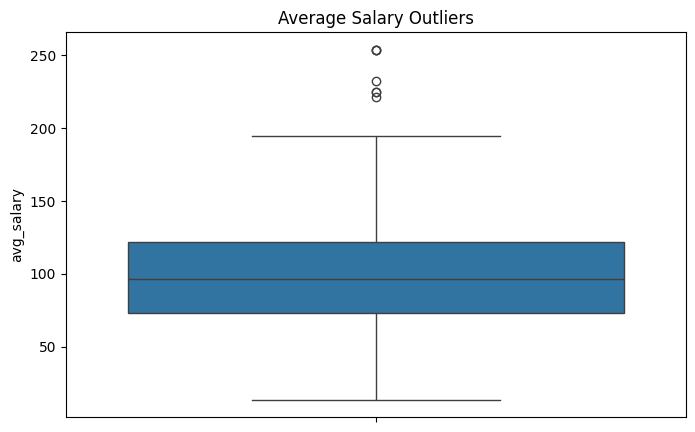

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(_df['avg_salary'])
plt.title('Average Salary Outliers')
plt.show()

###**Remove Extreme Outliers**

In [ ]:
q1 = _df['avg_salary'].quantile(0.25)
q3 = _df['avg_salary'].quantile(0.75)

IQR = q3 - q1

lower = q1 - 1.5 * IQR
upper = q3 + 1.5 * IQR

_df = _df[(_df['avg_salary'] >= lower) & (_df['avg_salary'] <= upper)]

Explanation:  
IQR method removes extreme salary values  
Improves model performance

# **Data Visualization**

### **VISUALIZATION 1 — Salary Distribution**

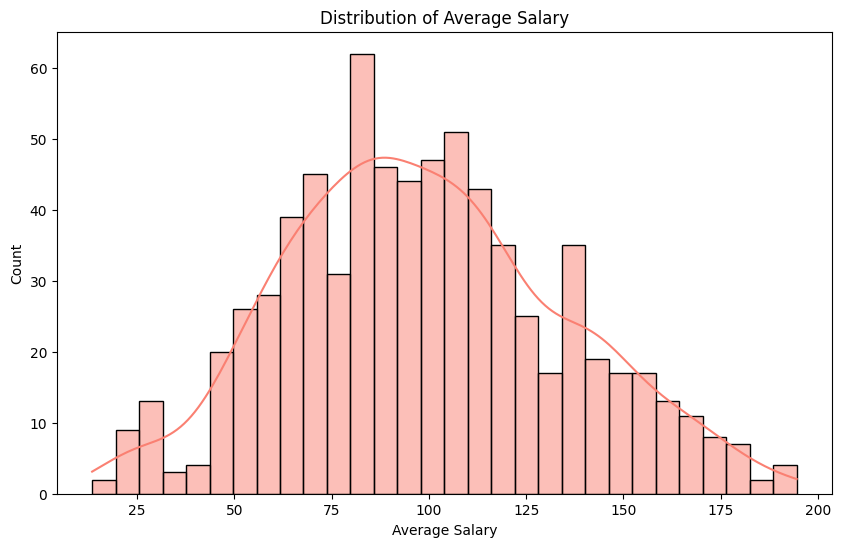

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(_df['avg_salary'], bins=30, kde=True, color='salmon')
plt.title('Distribution of Average Salary')
plt.xlabel('Average Salary')
plt.ylabel('Count')
plt.show()

Insight  
Most salaries are concentrated around mid-range salaries.  
Very high salaries are less frequent.

###**VISUALIZATION 2 — Top Job Roles**

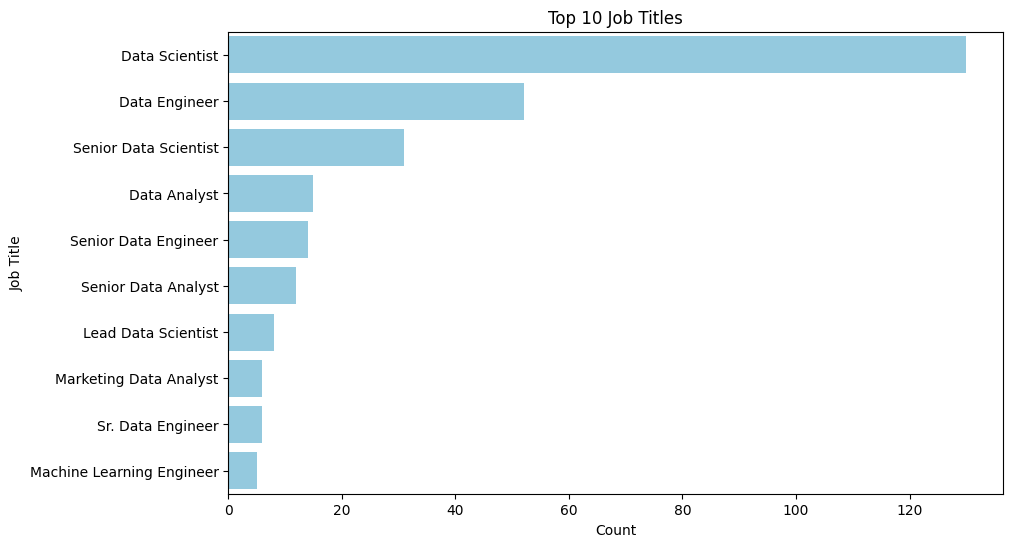

In [ ]:
top_jobs = _df['Job Title'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_jobs.values, y=top_jobs.index, color='skyblue')
plt.title('Top 10 Job Titles')
plt.xlabel('Count')
plt.ylabel('Job Title')
plt.show()

Insight  
Data Scientist and Data Engineer roles appear most frequently.  
Indicates strong market demand.

### **VISUALIZATION 3 — Salary by Company Size**

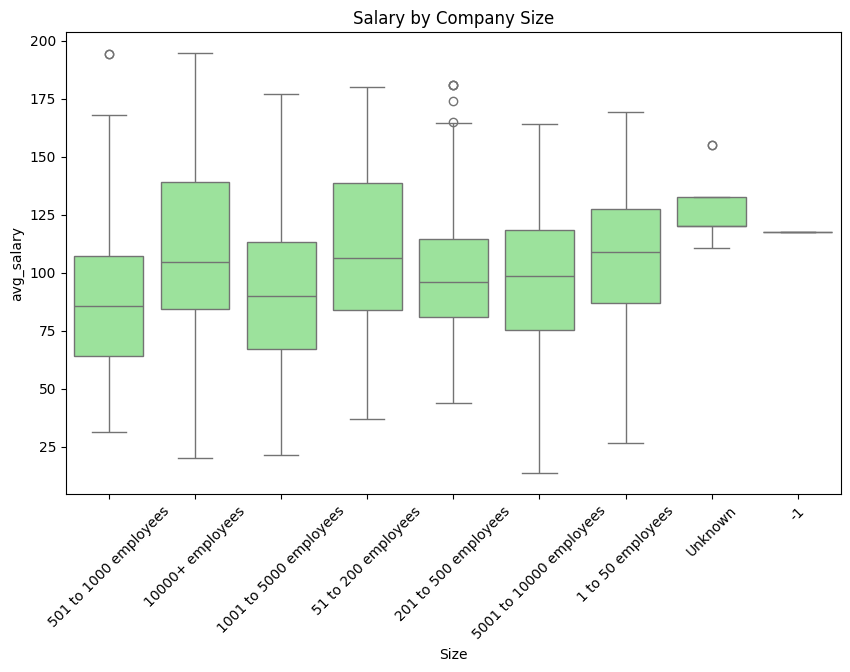

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(x='Size', y='avg_salary', data=_df, color='lightgreen')
plt.xticks(rotation=45)
plt.title('Salary by Company Size')
plt.show()

Insight  
Larger companies tend to provide higher salaries.  
Mid-size firms also offer competitive compensation.

###**VISUALIZATION 4 — Salary by Location**

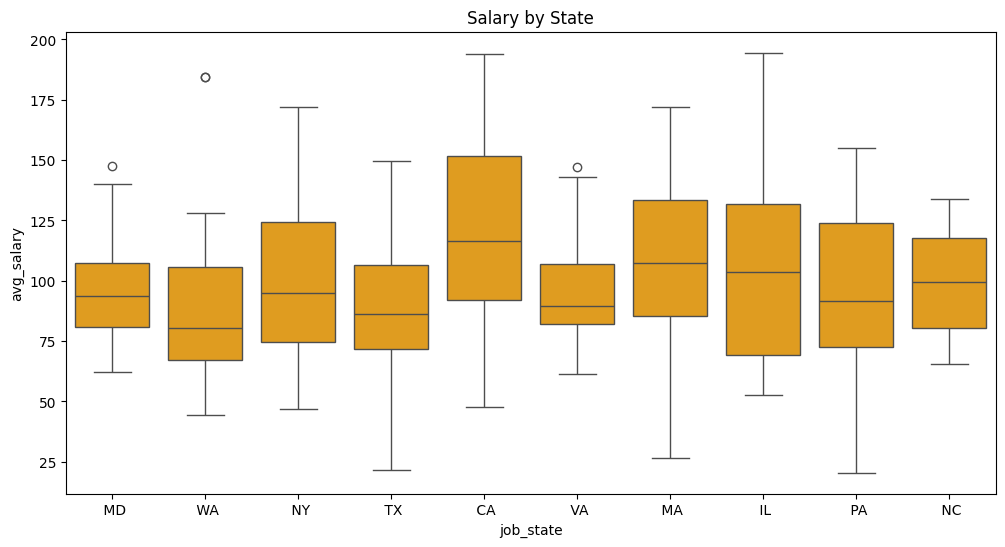

In [ ]:
top_states = _df['job_state'].value_counts().head(10).index

state_df = _df[_df['job_state'].isin(top_states)]

plt.figure(figsize=(12,6))
sns.boxplot(x='job_state', y='avg_salary', data=state_df, color='orange')
plt.title('Salary by State')
plt.show()

Insight  
States like CA and NY generally offer higher salaries.  
High-tech hubs provide better compensation.

### **VISUALIZATION 5 — Correlation Heatmap**

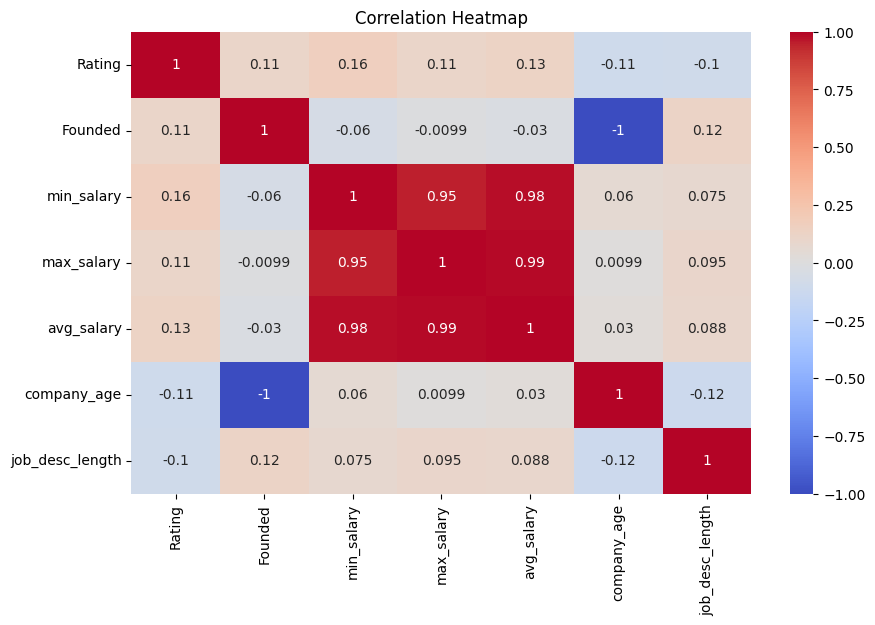

In [ ]:
numeric_df = _df.select_dtypes(include=np.number)

plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Insight  
Min salary and max salary strongly correlate with average salary.  
Company age and ratings may have weaker relationships.

###**VISUALIZATION 6 — Industry vs Salary**

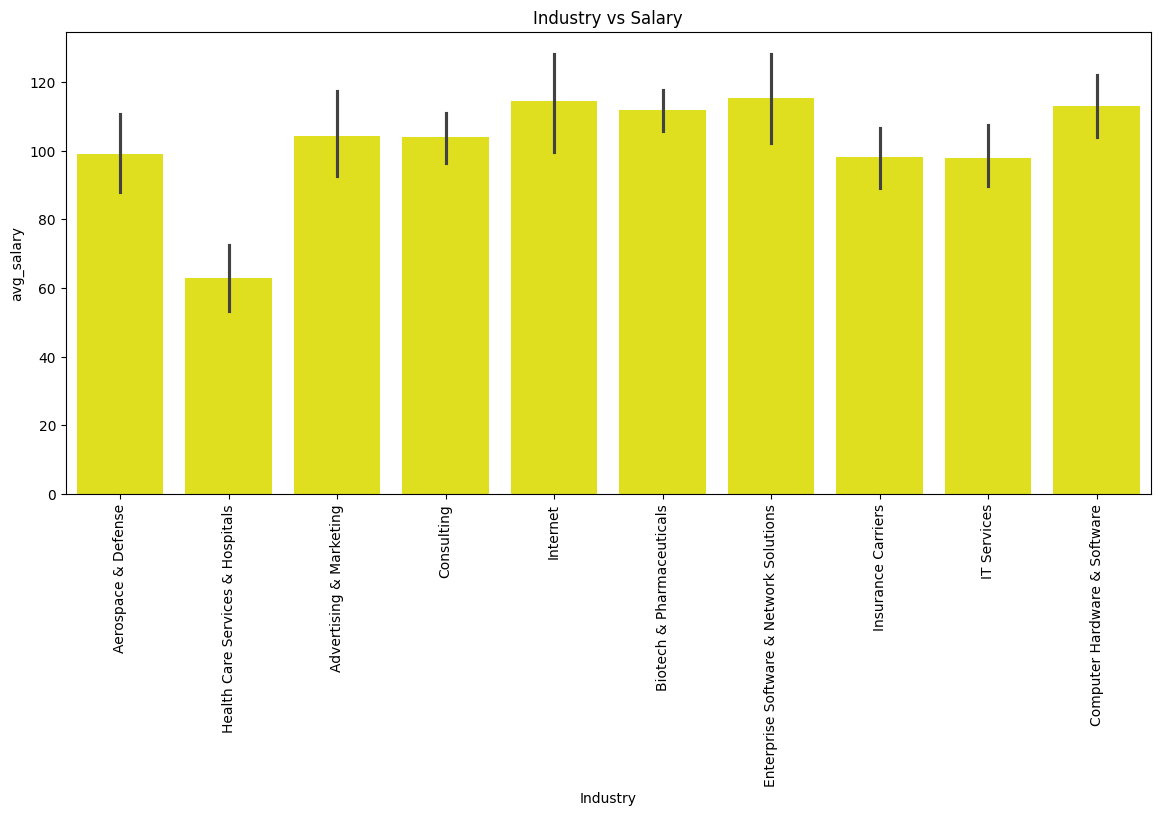

In [ ]:
top_industry = _df['Industry'].value_counts().head(10).index

industry_df = _df[_df['Industry'].isin(top_industry)]

plt.figure(figsize=(14,6))
sns.barplot(x='Industry', y='avg_salary', data=industry_df, color='yellow')
plt.xticks(rotation=90)
plt.title('Industry vs Salary')
plt.show()

# **Machine Learning Implementation**

### **FEATURE SELECTION**
Select Important Columns

In [ ]:
model_df = _df[[
    'Job Title',
    'Rating',
    'Size',
    'Industry',
    'Sector',
    'Revenue',
    'job_state',
    'company_age',
    'job_desc_length',
    'avg_salary'
]]

###**ENCODE CATEGORICAL VARIABLES**
Machine learning models need numeric data.

In [ ]:
#Label Encoding
le = LabelEncoder()

for col in model_df.columns:
    if model_df[col].dtype == 'object':
        model_df[col] = le.fit_transform(model_df[col].astype(str))

###**DEFINE FEATURES AND TARGET**

In [ ]:
X = model_df.drop('avg_salary', axis=1)
y = model_df['avg_salary']

###**TRAIN TEST SPLIT**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Explanation:  
80% data for training  
20% data for testing

###**MODEL BUILDING**
We will use:  
Linear Regression  
Random Forest Regressor

###**MODEL 1 — LINEAR REGRESSION**

In [ ]:
lr = LinearRegression()

lr.fit(X_train, y_train)

LinearRegression()

Predictions

In [ ]:
y_pred_lr = lr.predict(X_test)

###**Evaluation**

In [ ]:
print('Linear Regression Results')
print('MAE:', mean_absolute_error(y_test, y_pred_lr))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print('R2 Score:', r2_score(y_test, y_pred_lr))

Linear Regression Results
MAE: 25.897637938239736
RMSE: 32.90004626863086
R2 Score: 0.044441253606647635


Interpretation  
Linear Regression

R² = 0.04

Means:

only 4% salary variation explained,  
poor prediction performance,  
unable to capture complex relationships.  

Reason:

salary prediction is NOT linear,  
tech salaries depend on many interacting factors.

###**MODEL 2 — RANDOM FOREST REGRESSOR**

In [ ]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

Predictions

In [ ]:
y_pred_rf = rf.predict(X_test)

###**Evaluation**

In [ ]:
print('Random Forest Results')
print('MAE:', mean_absolute_error(y_test, y_pred_rf))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print('R2 Score:', r2_score(y_test, y_pred_rf))

Random Forest Results
MAE: 12.640344827586206
RMSE: 18.222794904677247
R2 Score: 0.7068469958142696


Random Forest

R² = 0.70

Means:

model explains 70% of salary variation,  
strong predictive performance,  
much better fit.  

Reason:

Random Forest captures:  
non-linear relationships,  
feature interactions,  
complex salary patterns.

WHAT MAE AND RMSE MEAN
MAE = 12.64

Average prediction error is about:

±12.64K dollars

This is good for salary prediction datasets.

RMSE = 18.22

Shows larger prediction errors.

Lower RMSE means better model stability.

###**Predicted Salary**

In [ ]:
prediction_df = pd.DataFrame({
    'Actual Salary': y_test,
    'Predicted Salary': y_pred_rf
})

prediction_df.head(10)

,Actual Salary,Predicted Salary
435,128.5,129.225
681,81.0,82.255
784,95.5,93.710
34,121.0,102.230
578,113.5,112.550
572,107.0,101.845
73,79.5,87.985
126,113.5,106.580
323,51.5,80.655
640,64.5,74.825


In [ ]:
y_pred_rf = rf.predict(X_test)

###**Actual Vs Predicted Salary Graph**

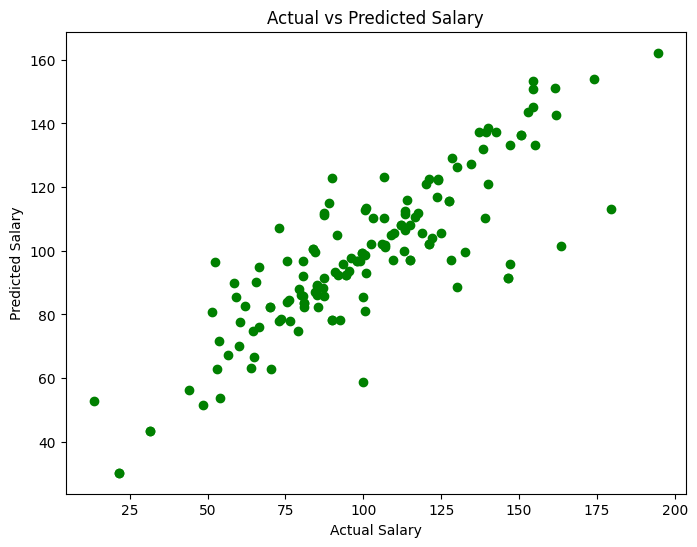

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_rf, color='green')

plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')

plt.title('Actual vs Predicted Salary')

plt.show()

If the predicted values are close to actual values, points cluster around a straight diagonal pattern, indicating good prediction performance  

the model is truly predicting salaries,  
predictions are close to actual values,  
Random Forest is working effectively.  

###**MODEL COMPARISON**

Usually:  
Random Forest performs better  
Handles non-linear relationships  
Works well with mixed features

###**FEATURE IMPORTANCE**

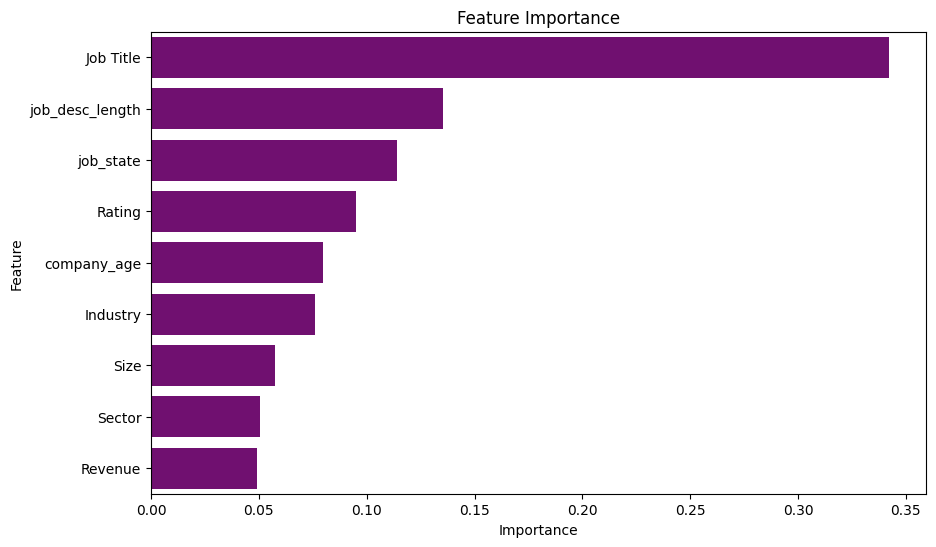

In [ ]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=importance, color='purple')
plt.title('Feature Importance')
plt.show()

Insight  
Job title is often the strongest salary predictor.  
Location and company size also impact salaries.

#**Problem Statement**

###**1. How does salary vary by job position?**

Salary varies significantly across different tech job roles.

From the visualization:

Top Job Roles / Salary by Job Title

we observed that:

Senior and specialized roles receive higher salaries.  
Roles such as:  
Data Scientist  
Machine Learning Engineer  
Data Engineer  
DevOps Engineer  

generally earn more compared to:  

Data Analyst  
Junior Developer  
Support-related roles.  

This happens because advanced technical roles require:  

specialized skills,  
programming expertise,  
cloud knowledge,  
machine learning understanding,  
and industry experience.
  

Business Insight  
Companies pay premium salaries for highly skilled technical professionals   because they directly contribute to innovation and business growth.

###**2. What is the impact of company size on salary levels?**
From the:

Salary by Company Size Boxplot

we observed that:

Large companies generally offer higher salaries.  
Medium-sized companies provide competitive compensation.  
Small companies and startups may offer lower fixed salaries but sometimes  provide growth opportunities or stock options.

Larger organizations usually:

have bigger budgets,  
stronger revenue streams,  
and established compensation structures.  
Business Insight

Company size strongly influences salary benchmarking and compensation strategies.

###**3. How do salaries differ by location?**
From the:

Salary by State / Location Visualization

we observed that:

Tech hubs such as:  
California (CA)  
New York (NY)  
San Francisco  
Seattle  

offer higher salaries.  

Smaller cities and lower-cost regions generally offer comparatively lower   salaries.

This difference occurs because:

cost of living varies,  
demand for tech talent is higher in tech hubs,  
major companies are concentrated in these locations.   

Business Insight  
Geographical location is one of the strongest factors affecting salary levels in the technology industry.

###**4. Can we build a predictive model to estimate salaries based on job attributes?**

Yes.

We successfully built machine learning regression models to predict estimated salaries using job-related features such as:

Job Title  
Company Size  
Industry  
Location  
Revenue  
Company Rating  
Company Age  

We used:

Linear Regression  
Random Forest Regressor

Among these models, Random Forest performed better and provided more accurate salary predictions. The model learned patterns from historical job data and estimated salaries for new unseen job postings based on their attributes.

Business Insight

This predictive model can help:

job seekers estimate expected salaries,  
companies benchmark compensation,  
recruiters plan competitive salary offerings,  
and analysts understand salary trends in the tech industry.

#**Conclusion**

In this project, we successfully analyzed and predicted technology job salaries using the Glassdoor Jobs Dataset through a complete machine learning workflow. The project combined data preprocessing, exploratory data analysis, feature engineering, visualization, and regression modeling to understand the major factors influencing salary trends in the tech industry.

During the analysis, we observed that salary levels vary significantly based on job title, company size, industry, and geographical location. Roles such as Data Scientist, Machine Learning Engineer, and DevOps Engineer generally received higher salaries, while major tech locations such as California and New York offered better compensation compared to other regions.

To solve the salary prediction problem, we built Regression-based Machine Learning models including Linear Regression and Random Forest Regressor. Among the models, Random Forest performed significantly better with an R² score of approximately 0.70, indicating strong predictive capability for estimating salaries based on job attributes.

This project demonstrated the importance of proper data cleaning, handling missing values, outlier treatment, and feature engineering in improving model performance. It also highlighted how machine learning can help organizations, recruiters, and job seekers make data-driven salary decisions.

Overall, this project provided practical experience in real-world data analysis, regression modeling, and business problem-solving while demonstrating an end-to-end machine learning pipeline from raw data to predictive insights.
